In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import hdbscan

In [ ]:
df = pd.read_csv('iris.csv')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [ ]:
# Fungsi visualisasi

def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

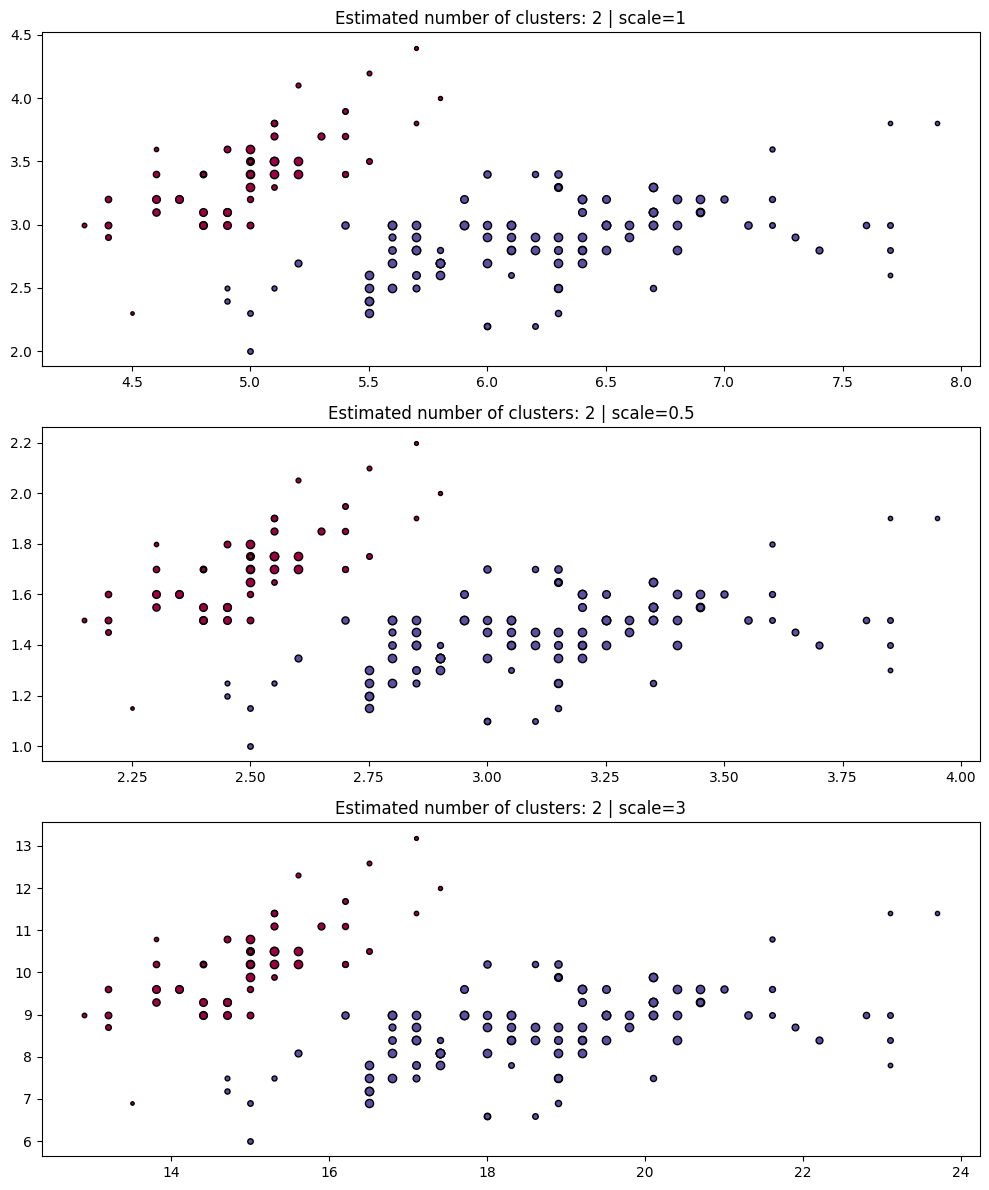

In [ ]:
# Mengambil seluruh fitur numerik
X = df.drop(columns=['species']).values

fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hasil = []

for idx, scale in enumerate([1, 0.5, 3]):
    # Membuat dan melatih model
    hdb = hdbscan.HDBSCAN()
    X_scaled = X * scale
    labels = hdb.fit_predict(X_scaled)

    # Visualisasi hasil clustering
    plot(
        X_scaled,
        labels,
        hdb.probabilities_,
        ax=axes[idx],
        parameters={"scale": scale}
    )

    # Menghitung jumlah cluster dan noise
    jumlah_cluster = len(set(labels)) - (1 if -1 in labels else 0)
    jumlah_noise = np.sum(labels == -1)
    persentase_noise = jumlah_noise / len(labels) * 100

    # Menyimpan hasil setiap percobaan
    hasil.append({
        'Skala': scale,
        'Jumlah Cluster': jumlah_cluster,
        'Jumlah Noise': jumlah_noise,
        'Noise (%)': round(persentase_noise, 2)
    })

plt.tight_layout()

In [ ]:
# Membuat tabel hasil clustering
hasil_df = pd.DataFrame(hasil)

# Menampilkan hasil setiap skala
print(hasil_df.to_string(index=False))

 Skala  Jumlah Cluster  Jumlah Noise  Noise (%)
   1.0               2             0        0.0
   0.5               2             0        0.0
   3.0               2             0        0.0


Berdasarkan percobaan menggunakan HDBSCAN pada dataset Iris, dilakukan clustering dengan tiga variasi skala, yaitu 1, 0,5, dan 3. Perubahan skala dilakukan dengan mengalikan seluruh fitur menggunakan nilai yang sama. Oleh karena itu, perbandingan jarak relatif antardata tetap terjaga. Jumlah cluster dan noise dibandingkan untuk mengetahui pengaruh perubahan skala terhadap hasil clustering. Data dengan label -1 dianggap sebagai noise dan tidak dihitung sebagai cluster.